# HT-9046MX — 1-Second Event Window & Response-Preserving Minute Features

วิเคราะห์ `Valve → pressure → temperature` จาก raw log ระดับหนึ่งวินาที และตอบคำถามว่า
จะลดข้อมูลเป็นหนึ่งแถวต่อนาทีอย่างไรโดยไม่ทำลายความสัมพันธ์ที่เกิดในระดับวินาที

หลักสำคัญจาก `README_System.md`:

- วิเคราะห์แยก `machine × module × SV`
- `ChangeValve` เป็น control sequence; ไม่ใช้ MValveHome, Valve ติดลบ หรือ Stop→Run เป็นหลักฐาน response ปกติ
- Valve เป็น command/position ไม่ใช่ flow meter
- ความสัมพันธ์ตามเวลาเป็น observed response ไม่ใช่การยืนยัน causality หรือ leak

## tl;dr

- Raw log มีช่วงห่าง 1 วินาที **98.55%** ของ interval ภายในไฟล์ที่ตรวจ
- พบจุดเริ่ม `ChangeValve` 2,971 ครั้ง แต่ผ่าน clean-window gate เพียง **243 events** จาก 12 เครื่อง
- เหตุการณ์ที่ผ่าน gate แบ่งเป็น closing 241 และ opening 2 events; ต้องดูสองทิศทางแยกกัน
- สำหรับ closing events ที่ +60 s ค่า median เป็น `Hp_2nd -10.9 psi` และ `Lp_2nd -12.7 psi`; ที่ +120 s เป็น `TempHigh -16.8` และ `TempLow +8.3`
- การเลือกเพียงแถวสุดท้ายของแต่ละนาทีทำให้ลำดับ valve → pressure ถูกบีบหาย วิธีรักษาความสัมพันธ์คือคำนวณ event/lag/microstructure features จากข้อมูล 1 วินาทีก่อน แล้วค่อยบันทึกเป็นหนึ่งแถวต่อ minute
- Simple correlation หลัง aggregate หนึ่งนาทีอาจสูงขึ้นจาก smoothing แต่ไม่ได้แปลว่าเก็บ response timing ได้ดีกว่า

**สถานะ:** Share with caveats — ใช้ยืนยันว่าการวิเคราะห์แบบ event window เห็น response ชัดกว่าการใช้ snapshot รายหนึ่งนาที แต่ยังขาด recipe/load/actual controlled temperature และ service labels.

## Context & Methods

### Window definition

```text
-30 s                    0 s                              +120 s
 pre-event reference     ChangeValve sequence starts      response horizon
 ├───────────────┬───────┼───────────────────────────────────┤
                 └ median -20:-5 s
```

Clean window ต้องผ่านทุกข้อ:

1. `Status=Run` อย่างน้อย 98% ของ window
2. `SV` คงที่ตลอด window
3. ไม่มี `MValveHome`, module `Off` หรือ Valve ติดลบ
4. ก่อน event เป็น module status `On` อย่างน้อย 90%
5. Valve เปลี่ยนสุทธิอย่างน้อย 3 command units
6. ไม่มี ChangeValve sequence ใหม่ซ้อนใน response horizon
7. timestamp coverage ครอบคลุมอย่างน้อย -27 ถึง +115 วินาที

Event ที่ไม่ผ่านจะไม่ถูกใช้วัด response แต่ยังนับไว้ใน candidate count เพื่อเห็น selection loss.

In [1]:
import importlib.util
import json
import sys
import subprocess
from pathlib import Path

required = {
    "numpy": "numpy", "pandas": "pandas", "polars": "polars",
    "matplotlib": "matplotlib", "seaborn": "seaborn", "scipy": "scipy",
}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from IPython.display import Markdown, display

PROJECT_ROOT_OVERRIDE = ""
DATASET_NAME = "HT9046MX-20260902T013607Z-1-001"

def find_project_root():
    candidates = [Path(PROJECT_ROOT_OVERRIDE)] if PROJECT_ROOT_OVERRIDE else []
    candidates += [Path.cwd(), Path.cwd().parent, Path("/content/OPERATION_P"), Path("/content/drive/MyDrive/OPERATION_P")]
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if (candidate / "README_System.md").exists():
            return candidate
    raise FileNotFoundError("ไม่พบ README_System.md — ตั้ง PROJECT_ROOT_OVERRIDE ให้ชี้ไปยัง OPERATION_P")

PROJECT_ROOT = find_project_root()
DATA_ROOT = PROJECT_ROOT / DATASET_NAME / "HT9046MX" / "raw" / "table=ht9046mx_readings"
OUTPUT_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_1s_window_analysis"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
CACHE_ROOT = OUTPUT_ROOT / "cache"
for folder in [OUTPUT_ROOT, FIGURE_ROOT, CACHE_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)

PRE_SECONDS = 30
POST_SECONDS = 120
MIN_VALVE_STEP = 3
CANDIDATE_CACHE_VERSION = "v1"
RESPONSE_CACHE_VERSION = "v2"

PALETTE = {
    "blue": "#2F6BFF", "gold": "#D79A24", "orange": "#E97932",
    "olive": "#7D8E45", "ink": "#243447", "light": "#DCE6F2", "grey": "#8796A5",
}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160, "axes.titleweight": "bold"})

MODULE_NAMES = {
    1: "Index L Arm1", 2: "Index R Arm1", 3: "Index L Arm2", 4: "Index R Arm2",
    5: "SH1", 6: "SH2", 7: "Hot1", 8: "Hot2",
}
TARGETS = ["hp2", "lp2", "temphi", "templo"]
TARGET_LABELS = {"hp2": "Hp_2nd", "lp2": "Lp_2nd", "temphi": "TempHigh", "templo": "TempLow"}

def savefig(name):
    path = FIGURE_ROOT / name
    plt.savefig(path, bbox_inches="tight", facecolor="white")
    return path

print("Project:", PROJECT_ROOT)
print("Raw data:", DATA_ROOT)
print("Outputs:", OUTPUT_ROOT)

Project: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P
Raw data: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\HT9046MX-20260902T013607Z-1-001\HT9046MX\raw\table=ht9046mx_readings
Outputs: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_1s_window_analysis


## Data

### 1. Discover raw files and verify timestamp cadence

In [2]:
files = sorted(DATA_ROOT.rglob("*.parquet"))
if not files:
    raise FileNotFoundError(f"ไม่พบ raw Parquet ใต้ {DATA_ROOT}")

all_machines = sorted({
    part.split("=", 1)[1]
    for path in files for part in path.parts if part.startswith("machine=")
})
print(f"Files: {len(files):,}; machines: {len(all_machines)}")
display(pd.DataFrame({"machine": all_machines}).T)

Files: 369; machines: 19


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
machine,017,022,024,029,041,056,057,058,063,070,071,072,081,082,083,115,118,119,124


### 2. Detect clean ChangeValve windows without loading all sensor columns

In [3]:
CANDIDATE_CACHE = CACHE_ROOT / f"candidate_events_{CANDIDATE_CACHE_VERSION}.parquet"
CADENCE_CACHE = CACHE_ROOT / f"cadence_{CANDIDATE_CACHE_VERSION}.json"

def build_candidate_cache(parquet_files):
    rows = []
    interval_counts = {"total_positive": 0, "exact_1s": 0, "two_seconds": 0, "gt_2s": 0}
    candidate_count = 0
    boundary_rejected = 0

    selected = ["machine_number", "recorded_at", "Status"]
    for module in range(1, 9):
        selected += [f"Valve_{module}", f"Status_{module}", f"SV_{module}"]

    for file_index, path in enumerate(parquet_files, start=1):
        raw = pl.read_parquet(path, columns=selected).sort("recorded_at")
        if raw.is_empty():
            continue
        machine = raw["machine_number"][0]
        timestamps = raw["recorded_at"].to_numpy()
        diffs = (np.diff(timestamps) / np.timedelta64(1, "s")).astype(float)
        positive = diffs[diffs > 0]
        interval_counts["total_positive"] += len(positive)
        interval_counts["exact_1s"] += int(np.isclose(positive, 1.0).sum())
        interval_counts["two_seconds"] += int(np.isclose(positive, 2.0).sum())
        interval_counts["gt_2s"] += int((positive > 2.0).sum())
        global_run = raw["Status"].to_numpy() == "Run"

        for module in range(1, 9):
            module_status = raw[f"Status_{module}"].to_numpy()
            sv = raw[f"SV_{module}"].to_numpy()
            valve = raw[f"Valve_{module}"].to_numpy().astype(float)
            event_starts = np.flatnonzero(
                (module_status == "ChangeValve")
                & np.r_[True, module_status[1:] != module_status[:-1]]
            )
            candidate_count += len(event_starts)

            for index in event_starts:
                if index < PRE_SECONDS or index + POST_SECONDS >= raw.height:
                    boundary_rejected += 1
                    continue
                window_slice = slice(index - PRE_SECONDS, index + POST_SECONDS + 1)
                relative_seconds = (
                    (timestamps[window_slice] - timestamps[index]) / np.timedelta64(1, "s")
                ).astype(float)
                if relative_seconds[0] > -27 or relative_seconds[-1] < 115:
                    continue
                if global_run[window_slice].mean() < 0.98:
                    continue
                if len(set(sv[window_slice])) != 1:
                    continue
                if np.any(np.isin(module_status[window_slice], ["MValveHome", "Off"])):
                    continue
                if (module_status[index - 20:index] == "On").mean() < 0.90:
                    continue
                if np.nanmin(valve[window_slice]) < 0:
                    continue

                pre_valve = float(np.nanmedian(valve[index - 20:index - 5]))
                post_valve = float(np.nanmedian(valve[index + 10:index + 31]))
                valve_step = post_valve - pre_valve
                if abs(valve_step) < MIN_VALVE_STEP:
                    continue
                second_start = np.any(
                    (module_status[index + 1:index + POST_SECONDS + 1] == "ChangeValve")
                    & (module_status[index:index + POST_SECONDS] != "ChangeValve")
                )
                if second_start:
                    continue

                rows.append({
                    "relative_file": path.relative_to(DATA_ROOT).as_posix(),
                    "machine_number": machine,
                    "module": module,
                    "event_at": timestamps[index],
                    "sv": str(sv[index]),
                    "pre_valve": pre_valve,
                    "post_valve": post_valve,
                    "valve_step": valve_step,
                    "direction": "Opening" if valve_step > 0 else "Closing",
                })

        if file_index % 50 == 0 or file_index == len(parquet_files):
            print(f"Candidate pass: {file_index:,}/{len(parquet_files):,} files; clean so far={len(rows):,}")

    candidates = pl.from_pandas(pd.DataFrame(rows)).with_columns(
        pl.col("module").cast(pl.Int8),
        pl.col("event_at").cast(pl.Datetime("us")),
    )
    candidates.write_parquet(CANDIDATE_CACHE, compression="zstd")
    cadence = {
        **interval_counts,
        "candidate_event_count": candidate_count,
        "clean_event_count": candidates.height,
        "file_boundary_rejected": boundary_rejected,
    }
    CADENCE_CACHE.write_text(json.dumps(cadence, indent=2), encoding="utf-8")
    return candidates, cadence

if CANDIDATE_CACHE.exists() and CADENCE_CACHE.exists():
    candidate_events = pl.read_parquet(CANDIDATE_CACHE)
    cadence = json.loads(CADENCE_CACHE.read_text(encoding="utf-8"))
else:
    candidate_events, cadence = build_candidate_cache(files)

one_second_pct = 100 * cadence["exact_1s"] / cadence["total_positive"]
display(pd.DataFrame({
    "Measure": ["Positive timestamp intervals", "Exactly 1 second", "2 seconds", ">2 seconds", "ChangeValve starts", "Clean windows"],
    "Value": [cadence["total_positive"], cadence["exact_1s"], cadence["two_seconds"], cadence["gt_2s"], cadence["candidate_event_count"], candidate_events.height],
}))
print(f"Exact one-second cadence: {one_second_pct:.3f}%")

,Measure,Value
0,Positive timestamp intervals,26159047
1,Exactly 1 second,25780925
2,2 seconds,375963
3,>2 seconds,2159
4,ChangeValve starts,2971
5,Clean windows,243


Exact one-second cadence: 98.555%


### 3. Extract pressure and temperature trajectories only for accepted windows

In [4]:
EVENT_CACHE = CACHE_ROOT / f"event_summary_{RESPONSE_CACHE_VERSION}.parquet"
TRAJECTORY_CACHE = CACHE_ROOT / f"event_trajectories_{RESPONSE_CACHE_VERSION}.parquet"

def robust_iqr(values):
    values = np.asarray(values, dtype=float)
    return float(np.nanpercentile(values, 75) - np.nanpercentile(values, 25))

def local_median(relative_seconds, values, center, radius=2):
    mask = (relative_seconds >= center - radius) & (relative_seconds <= center + radius)
    return float(np.nanmedian(values[mask])) if mask.any() else np.nan

def window_slope(relative_seconds, values, start, end):
    values = np.asarray(values, dtype=float)
    mask = (
        (relative_seconds >= start) & (relative_seconds <= end)
        & np.isfinite(values)
    )
    if mask.sum() < 5 or np.unique(relative_seconds[mask]).size < 2:
        return np.nan
    return float(np.polyfit(relative_seconds[mask], values[mask], 1)[0])

def best_lagged_spearman(relative_seconds, valve_delta, target_delta, max_lag=60):
    valve_series = pd.Series(np.asarray(valve_delta, dtype=float), index=relative_seconds).groupby(level=0).median()
    target_series = pd.Series(np.asarray(target_delta, dtype=float), index=relative_seconds).groupby(level=0).median()
    base_seconds = np.arange(0, 61)
    best = (np.nan, np.nan)
    best_abs = -np.inf
    for lag in range(0, max_lag + 1, 5):
        paired = pd.DataFrame({
            "valve": valve_series.reindex(base_seconds).to_numpy(),
            "target": target_series.reindex(base_seconds + lag).to_numpy(),
        }).dropna()
        if len(paired) < 20 or paired["valve"].nunique() < 3 or paired["target"].nunique() < 3:
            continue
        rho = float(spearmanr(paired["valve"], paired["target"]).statistic)
        if np.isfinite(rho) and abs(rho) > best_abs:
            best_abs = abs(rho)
            best = (float(lag), rho)
    return best

def build_response_cache(candidates):
    candidate_pd = candidates.to_pandas()
    event_rows = []
    trajectory_rows = []
    grouped_files = list(candidate_pd.groupby("relative_file", sort=True))

    for file_index, (relative_file, file_events) in enumerate(grouped_files, start=1):
        modules = sorted(file_events["module"].astype(int).unique())
        selected = ["recorded_at"]
        for module in modules:
            selected += [
                f"Valve_{module}", f"Hp_1st_{module}", f"Lp_1st_{module}",
                f"Hp_2nd_{module}", f"Lp_2nd_{module}", f"TempHi_{module}", f"TempLo_{module}",
            ]
        raw = pl.read_parquet(DATA_ROOT / relative_file, columns=selected).sort("recorded_at")
        timestamps = raw["recorded_at"].to_numpy()

        for event in file_events.itertuples(index=False):
            event_time = np.datetime64(event.event_at.to_datetime64())
            index = int(np.searchsorted(timestamps, event_time))
            if index >= len(timestamps) or timestamps[index] != event_time:
                continue
            lo = max(0, index - PRE_SECONDS - 5)
            hi = min(len(timestamps), index + POST_SECONDS + 6)
            observed_times = timestamps[lo:hi]
            relative_seconds = np.rint(
                (observed_times - event_time) / np.timedelta64(1, "s")
            ).astype(int)
            keep = (relative_seconds >= -PRE_SECONDS) & (relative_seconds <= POST_SECONDS)
            relative_seconds = relative_seconds[keep]
            observed_times = observed_times[keep]
            module = int(event.module)
            arrays = {
                "valve": raw[f"Valve_{module}"].cast(pl.Float64).to_numpy()[lo:hi][keep],
                "hp1": raw[f"Hp_1st_{module}"].cast(pl.Float64).to_numpy()[lo:hi][keep],
                "lp1": raw[f"Lp_1st_{module}"].cast(pl.Float64).to_numpy()[lo:hi][keep],
                "hp2": raw[f"Hp_2nd_{module}"].cast(pl.Float64).to_numpy()[lo:hi][keep],
                "lp2": raw[f"Lp_2nd_{module}"].cast(pl.Float64).to_numpy()[lo:hi][keep],
                "temphi": raw[f"TempHi_{module}"].cast(pl.Float64).to_numpy()[lo:hi][keep],
                "templo": raw[f"TempLo_{module}"].cast(pl.Float64).to_numpy()[lo:hi][keep],
            }
            pre_mask = (relative_seconds >= -20) & (relative_seconds <= -5)
            baselines = {name: float(np.nanmedian(values[pre_mask])) for name, values in arrays.items()}
            event_id = f"MX{event.machine_number}_M{module}_{pd.Timestamp(event.event_at).strftime('%Y%m%dT%H%M%S')}"
            summary_row = {
                "event_id": event_id,
                "machine_number": str(event.machine_number), "module": module,
                "event_at": pd.Timestamp(event.event_at), "sv": event.sv,
                "direction": event.direction, "valve_step": float(event.valve_step),
                "observed_seconds": int(len(relative_seconds)),
            }
            post_mask = relative_seconds >= 0
            post_valve = arrays["valve"][post_mask]
            summary_row["valve_total_variation"] = float(np.nansum(np.abs(np.diff(post_valve))))
            summary_row["valve_step_count"] = int(np.nansum(np.abs(np.diff(post_valve)) >= 0.5))
            summary_row["valve_post_slope_30s"] = window_slope(relative_seconds, arrays["valve"], 0, 30)
            for target in TARGETS:
                baseline = baselines[target]
                pre_iqr = robust_iqr(arrays[target][pre_mask])
                summary_row[f"{target}_pre_iqr"] = pre_iqr
                summary_row[f"{target}_pre_slope"] = window_slope(relative_seconds, arrays[target], -20, -5)
                summary_row[f"{target}_post_slope_30s"] = window_slope(relative_seconds, arrays[target], 0, 30)
                for lag in [5, 15, 30, 60, 120]:
                    summary_row[f"{target}_response_{lag}s"] = local_median(relative_seconds, arrays[target], lag) - baseline
                post_delta = arrays[target][post_mask] - baseline
                if np.isfinite(post_delta).any():
                    peak_position = int(np.nanargmax(np.abs(post_delta)))
                    summary_row[f"{target}_peak_abs"] = float(abs(post_delta[peak_position]))
                    summary_row[f"{target}_peak_lag_s"] = int(relative_seconds[post_mask][peak_position])
                else:
                    summary_row[f"{target}_peak_abs"] = np.nan
                    summary_row[f"{target}_peak_lag_s"] = np.nan
                best_lag, best_rho = best_lagged_spearman(
                    relative_seconds,
                    arrays["valve"] - baselines["valve"],
                    arrays[target] - baseline,
                )
                summary_row[f"{target}_best_lag_s"] = best_lag
                summary_row[f"{target}_best_lag_rho"] = best_rho

            event_rows.append(summary_row)
            for row_index, relative_second in enumerate(relative_seconds):
                trajectory_row = {
                    "event_id": event_id, "machine_number": str(event.machine_number),
                    "module": module, "event_at": pd.Timestamp(event.event_at),
                    "observed_at": pd.Timestamp(observed_times[row_index]),
                    "sv": event.sv, "direction": event.direction,
                    "relative_second": int(relative_second),
                    "valve_delta": float(arrays["valve"][row_index] - baselines["valve"]),
                }
                for target in TARGETS:
                    trajectory_row[f"{target}_delta"] = float(arrays[target][row_index] - baselines[target])
                trajectory_rows.append(trajectory_row)

        if file_index % 25 == 0 or file_index == len(grouped_files):
            print(f"Response pass: {file_index:,}/{len(grouped_files):,} files")

    event_summary = pl.from_pandas(pd.DataFrame(event_rows))
    trajectories = pl.from_pandas(pd.DataFrame(trajectory_rows))
    event_summary.write_parquet(EVENT_CACHE, compression="zstd")
    trajectories.write_parquet(TRAJECTORY_CACHE, compression="zstd")
    return event_summary, trajectories

if EVENT_CACHE.exists() and TRAJECTORY_CACHE.exists():
    event_summary = pl.read_parquet(EVENT_CACHE)
    trajectories = pl.read_parquet(TRAJECTORY_CACHE)
else:
    event_summary, trajectories = build_response_cache(candidate_events)

event_pd = event_summary.to_pandas()
trajectory_pd = trajectories.to_pandas()
print(f"Clean events with extracted response: {len(event_pd):,}")
display(event_pd.head(8))

Response pass: 25/51 files


Response pass: 50/51 files


Response pass: 51/51 files


Clean events with extracted response: 243


,event_id,machine_number,module,event_at,sv,direction,valve_step,observed_seconds,valve_total_variation,valve_step_count,...,templo_post_slope_30s,templo_response_5s,templo_response_15s,templo_response_30s,templo_response_60s,templo_response_120s,templo_peak_abs,templo_peak_lag_s,templo_best_lag_s,templo_best_lag_rho
0,MX017_M4_20260810T203546,017,4,2026-08-10 20:35:46,Off,Closing,-88.0,149,158.0,17,...,0.062354,0.00,-0.30,2.20,9.30,21.90,22.00,120,30.0,-0.625650
1,MX017_M8_20260820T040647,017,8,2026-08-20 04:06:47,Off,Closing,-99.0,149,179.0,20,...,0.133831,-0.10,0.40,3.90,11.50,19.50,19.60,116,60.0,-0.654820
2,MX017_M8_20260820T075036,017,8,2026-08-20 07:50:36,Off,Closing,-98.0,149,193.0,20,...,0.102735,-1.00,-0.80,2.30,10.80,12.00,16.80,91,55.0,-0.653938
3,MX017_M8_20260820T094425,017,8,2026-08-20 09:44:25,Off,Closing,-96.0,149,179.0,20,...,0.166221,0.10,1.00,4.95,13.30,21.20,21.40,111,60.0,-0.654686
4,MX017_M8_20260821T201551,017,8,2026-08-21 20:15:51,Off,Closing,-97.0,149,187.0,20,...,0.142816,-0.70,-0.20,3.70,11.80,13.30,18.00,91,50.0,-0.653881
5,MX017_M1_20260830T010719,017,1,2026-08-30 01:07:19,Off,Closing,-97.0,148,184.0,20,...,0.148185,-0.10,0.30,4.30,11.10,20.20,20.20,119,60.0,-0.653652
6,MX017_M1_20260830T012336,017,1,2026-08-30 01:23:36,Off,Closing,-90.0,149,211.0,23,...,0.083794,1.85,2.65,3.95,6.45,10.05,10.15,104,60.0,-0.629180
7,MX017_M2_20260830T012336,017,2,2026-08-30 01:23:36,Off,Closing,-89.0,149,195.0,21,...,-0.288503,-3.25,-7.85,-9.65,-6.65,2.25,9.65,28,60.0,-0.625705


## Results

### 4. How much clean event evidence exists per machine and module?

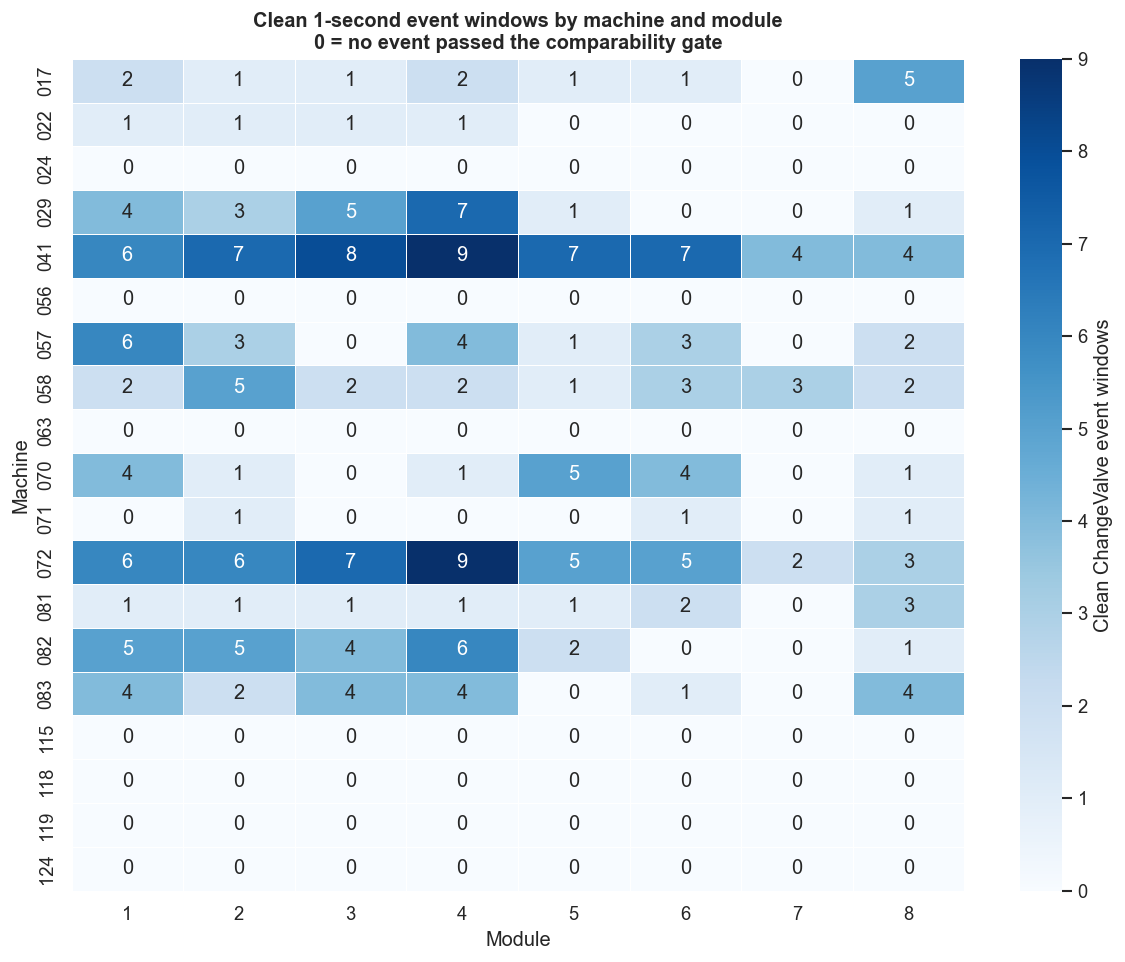

,direction,events
0,Closing,241
1,Opening,2


In [5]:
coverage = (
    event_pd.groupby(["machine_number", "module"]).size()
    .unstack(fill_value=0).reindex(index=all_machines, columns=range(1, 9), fill_value=0)
)
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(coverage, cmap="Blues", annot=True, fmt="d", linewidths=.4,
            cbar_kws={"label": "Clean ChangeValve event windows"}, ax=ax)
ax.set_title("Clean 1-second event windows by machine and module\n0 = no event passed the comparability gate")
ax.set_xlabel("Module")
ax.set_ylabel("Machine")
savefig("01_clean_event_coverage.png")
plt.show()

direction_counts = event_pd["direction"].value_counts().reindex(["Closing", "Opening"], fill_value=0)
display(pd.DataFrame({"direction": direction_counts.index, "events": direction_counts.values}))

**วิธีอ่าน:** จำนวนศูนย์ไม่ได้หมายความว่า module ไม่มี valve response แต่หมายถึงไม่มี event ที่ผ่าน gate เข้มงวดในช่วงข้อมูลนี้
เครื่องที่มีวันน้อยหรือไม่มี clean event ไม่ควรใช้สร้าง response baseline; ใช้เป็น external/shadow test เท่านั้น.

### 5. Closing-event pressure response by machine and module

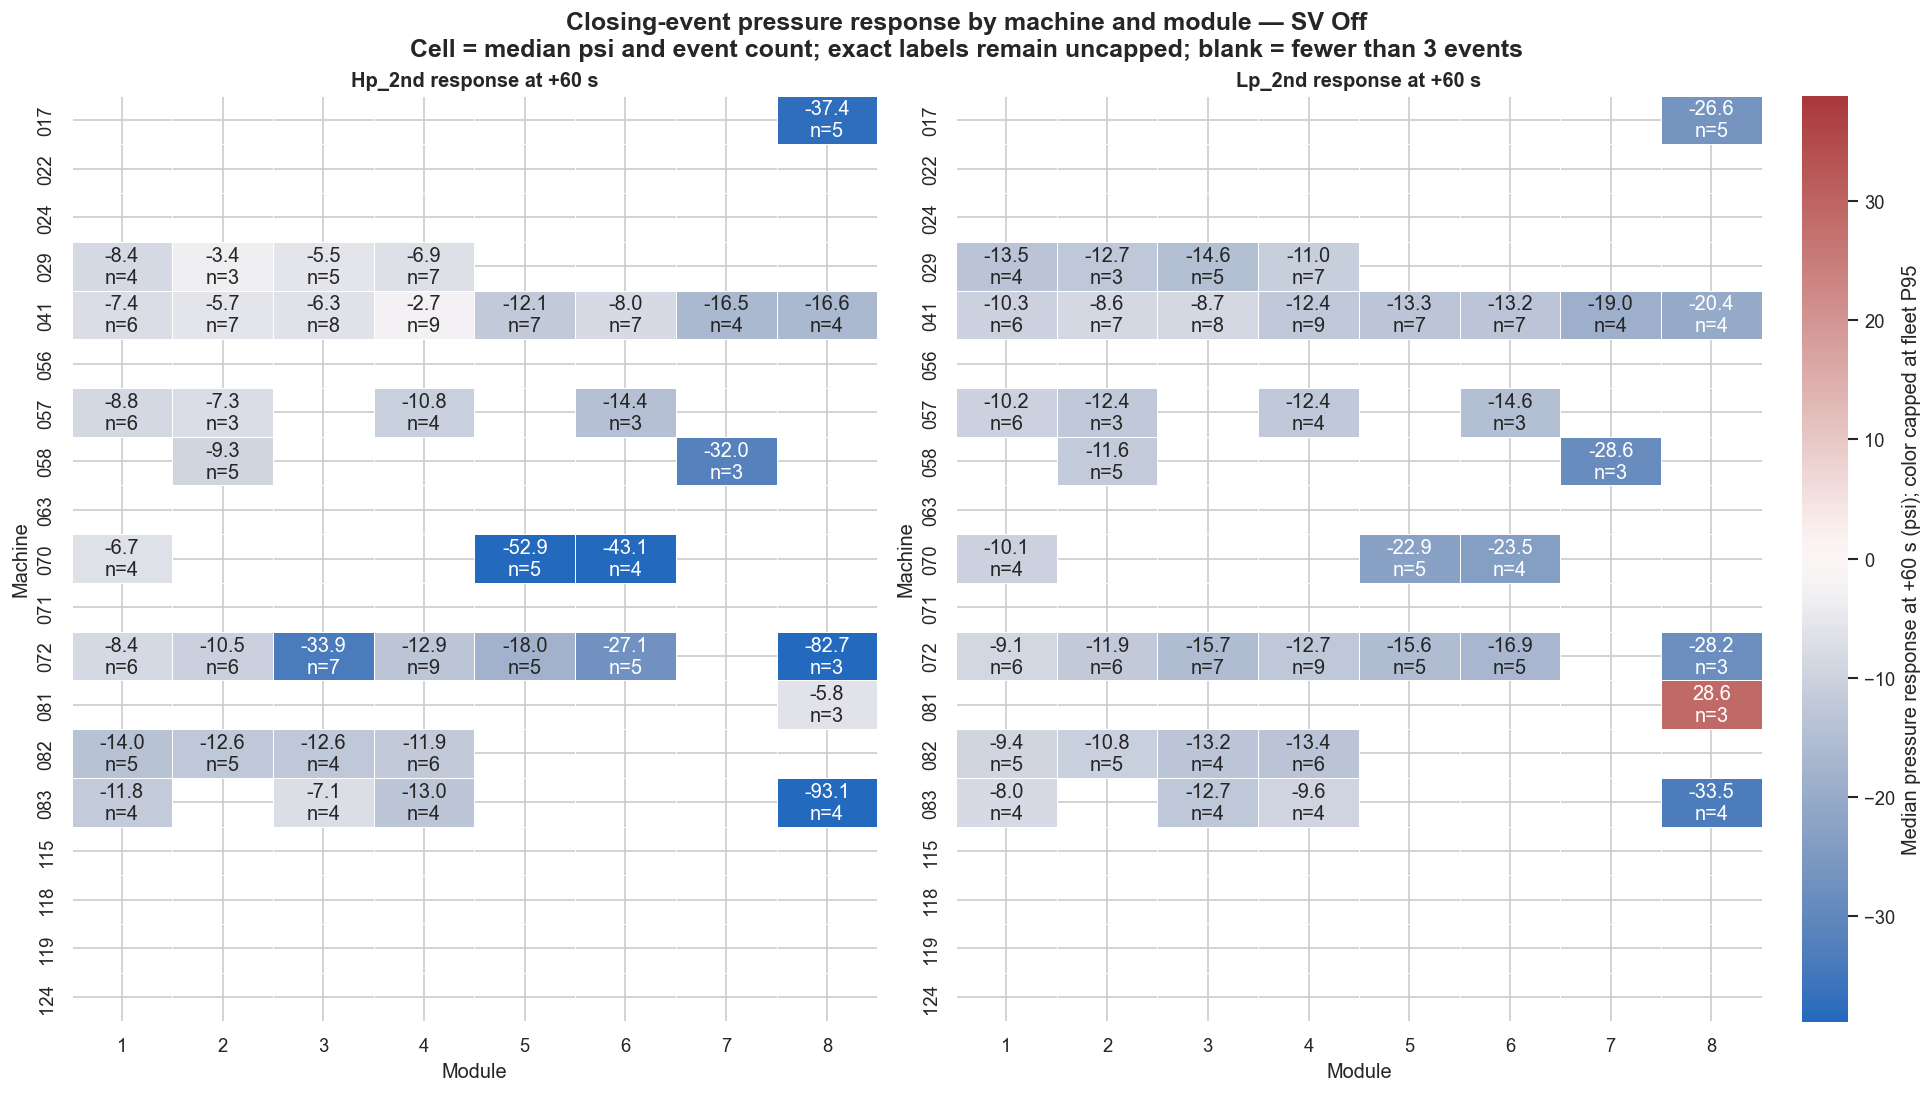

In [6]:
closing_events = event_pd[(event_pd["direction"] == "Closing") & (event_pd["sv"] == "Off")].copy()
profile_response = (
    closing_events.groupby(["machine_number", "module"], as_index=False)
    .agg(
        events=("event_id", "nunique"),
        hp2_response_60s=("hp2_response_60s", "median"),
        lp2_response_60s=("lp2_response_60s", "median"),
    )
)
eligible_profile_response = profile_response[profile_response["events"] >= 3].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 9), constrained_layout=True)
response_limit = max(
    20,
    np.nanpercentile(np.abs(eligible_profile_response[["hp2_response_60s", "lp2_response_60s"]]), 95),
)
for ax, metric, label in [
    (axes[0], "hp2_response_60s", "Hp_2nd"),
    (axes[1], "lp2_response_60s", "Lp_2nd"),
]:
    heat = eligible_profile_response.pivot(index="machine_number", columns="module", values=metric)
    heat = heat.reindex(index=all_machines, columns=range(1, 9))
    event_heat = eligible_profile_response.pivot(index="machine_number", columns="module", values="events")
    event_heat = event_heat.reindex(index=all_machines, columns=range(1, 9))
    annotations = heat.copy().astype(object)
    for machine in heat.index:
        for module in heat.columns:
            if pd.isna(heat.loc[machine, module]):
                annotations.loc[machine, module] = ""
            else:
                annotations.loc[machine, module] = f"{heat.loc[machine, module]:.1f}\nn={int(event_heat.loc[machine, module])}"
    sns.heatmap(
        heat, cmap="vlag", center=0, vmin=-response_limit, vmax=response_limit,
        annot=annotations, fmt="", linewidths=.4, cbar=ax is axes[1],
        cbar_kws={"label": "Median pressure response at +60 s (psi); color capped at fleet P95"}, ax=ax,
    )
    ax.set_title(f"{label} response at +60 s")
    ax.set_xlabel("Module")
    ax.set_ylabel("Machine")
fig.suptitle(
    "Closing-event pressure response by machine and module — SV Off\n"
    "Cell = median psi and event count; exact labels remain uncapped; blank = fewer than 3 events",
    fontsize=15, fontweight="bold",
)
savefig("02_profile_pressure_response_60s.png")
plt.show()

profile_response.to_csv(OUTPUT_ROOT / "profile_pressure_response_60s.csv", index=False)

Heatmap นี้แสดงว่าทิศทางและขนาด response ไม่เท่ากันทุกเครื่อง/โมดูล แม้คัดเฉพาะ `SV=OFF` และ closing sequence แล้ว
จึงควรสร้าง response calibration ราย machine × module และไม่ใช้ fleet-wide gain/lag threshold ตัวเดียว.

### 6. Event-aligned response at one-second grain

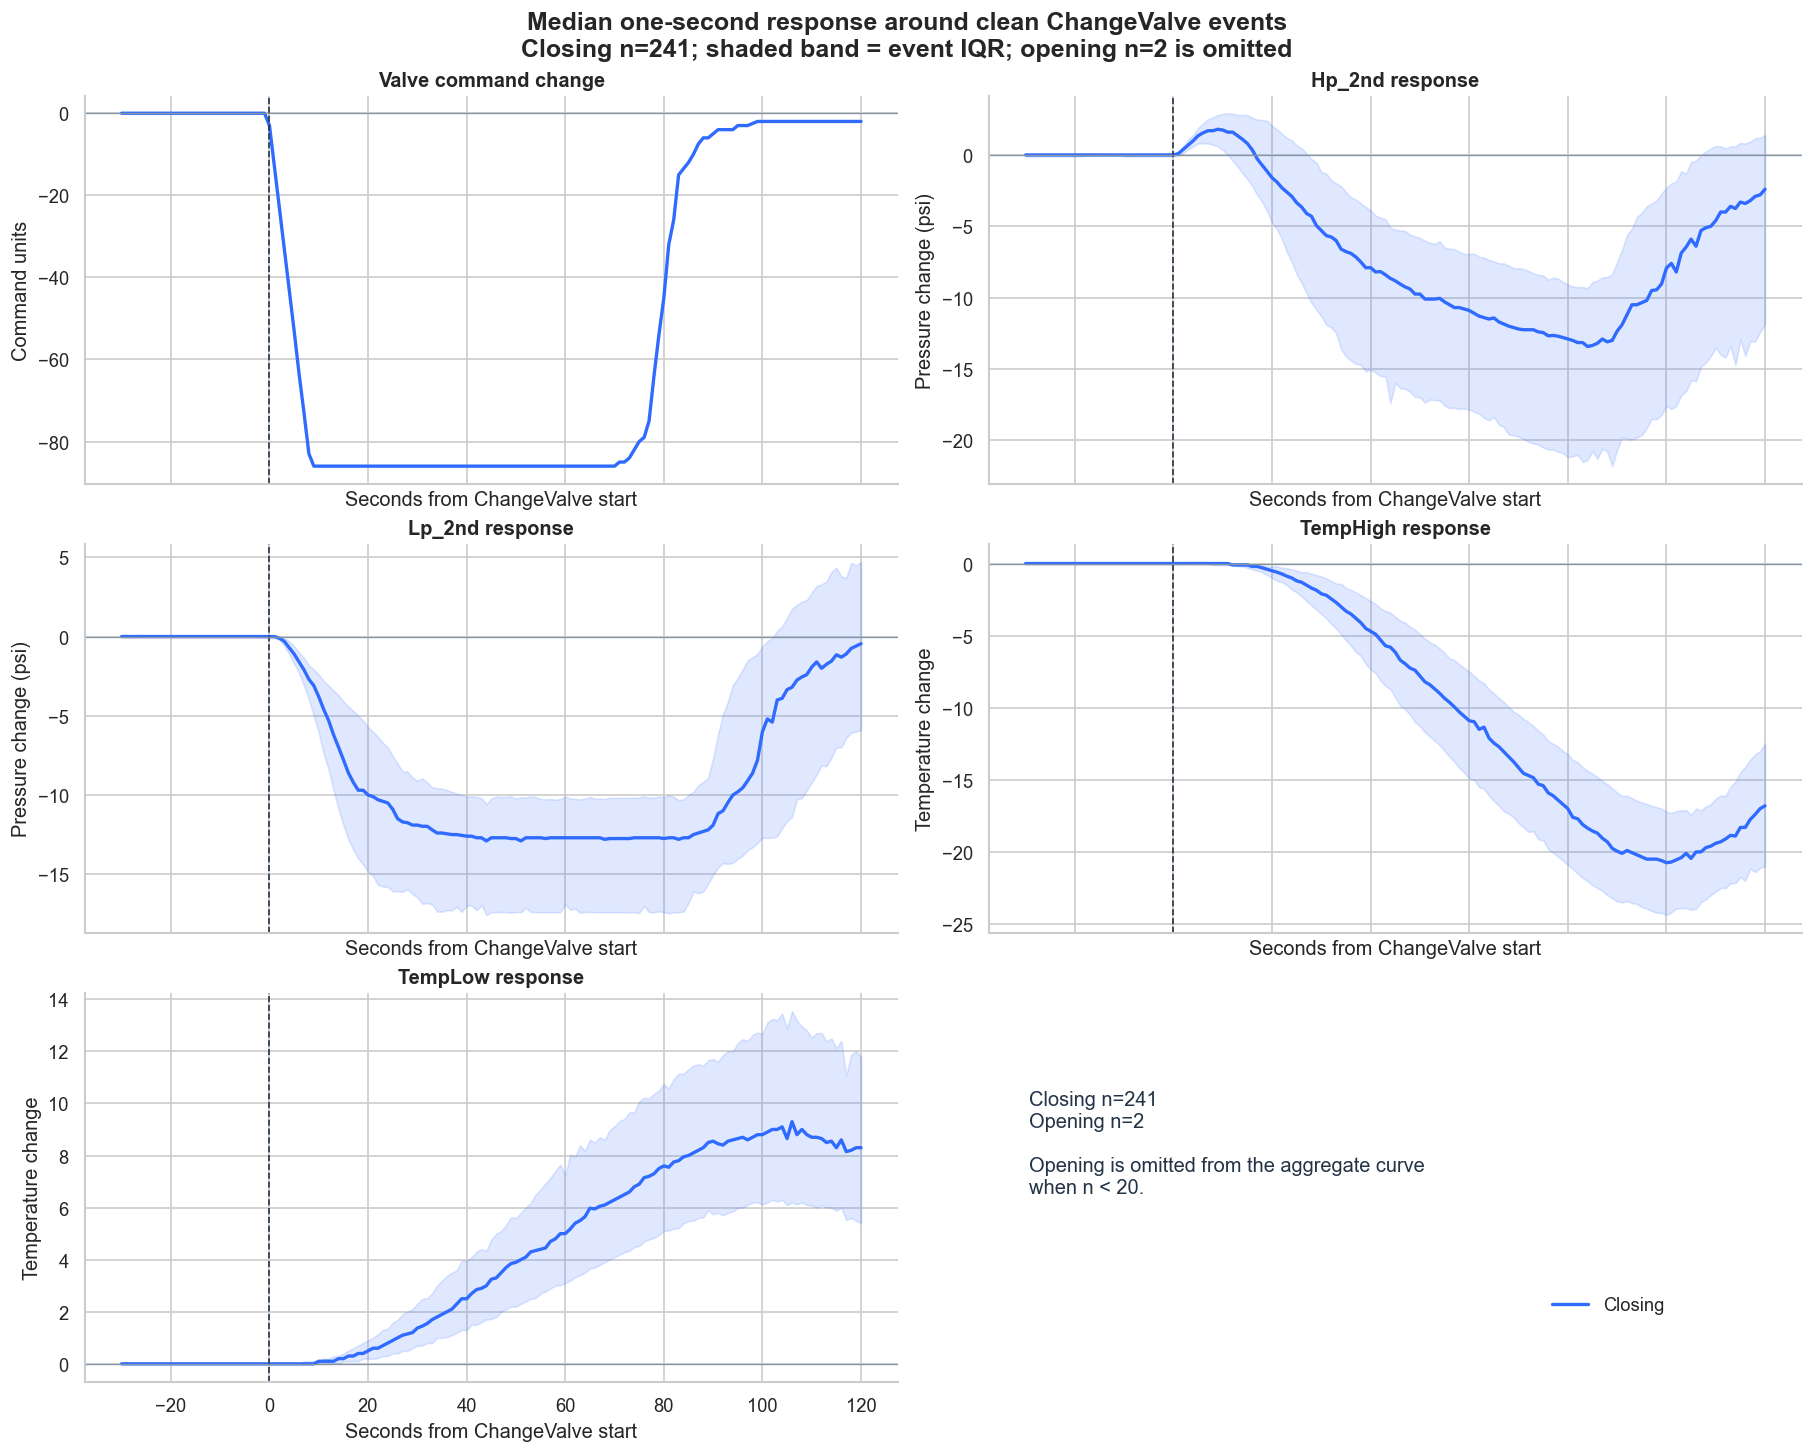

In [7]:
curve = (
    trajectory_pd.groupby(["direction", "relative_second"])
    .agg(
        events=("event_id", "nunique"),
        valve_median=("valve_delta", "median"),
        hp2_median=("hp2_delta", "median"), hp2_q25=("hp2_delta", lambda s: s.quantile(.25)), hp2_q75=("hp2_delta", lambda s: s.quantile(.75)),
        lp2_median=("lp2_delta", "median"), lp2_q25=("lp2_delta", lambda s: s.quantile(.25)), lp2_q75=("lp2_delta", lambda s: s.quantile(.75)),
        temphi_median=("temphi_delta", "median"), temphi_q25=("temphi_delta", lambda s: s.quantile(.25)), temphi_q75=("temphi_delta", lambda s: s.quantile(.75)),
        templo_median=("templo_delta", "median"), templo_q25=("templo_delta", lambda s: s.quantile(.25)), templo_q75=("templo_delta", lambda s: s.quantile(.75)),
    ).reset_index()
)

fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True, constrained_layout=True)
plot_specs = [
    ("valve", "Valve command change", "Command units"),
    ("hp2", "Hp_2nd response", "Pressure change (psi)"),
    ("lp2", "Lp_2nd response", "Pressure change (psi)"),
    ("temphi", "TempHigh response", "Temperature change"),
    ("templo", "TempLow response", "Temperature change"),
]
colors = {"Closing": PALETTE["blue"], "Opening": PALETTE["orange"]}
plottable_directions = [direction for direction in ["Closing", "Opening"] if direction_counts[direction] >= 20]
for ax, (metric, title, ylabel) in zip(axes.ravel(), plot_specs):
    for direction in plottable_directions:
        part = curve[curve["direction"] == direction]
        if part.empty:
            continue
        median_column = f"{metric}_median"
        ax.plot(part["relative_second"], part[median_column], color=colors[direction], lw=2, label=direction)
        if metric != "valve":
            ax.fill_between(part["relative_second"], part[f"{metric}_q25"], part[f"{metric}_q75"],
                            color=colors[direction], alpha=.15)
    ax.axvline(0, color=PALETTE["ink"], ls="--", lw=1)
    ax.axhline(0, color=PALETTE["grey"], lw=.8)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Seconds from ChangeValve start")
    sns.despine(ax=ax)
axes.ravel()[-1].axis("off")
axes.ravel()[-1].text(
    .05, .75,
    f"Closing n={direction_counts['Closing']:,}\nOpening n={direction_counts['Opening']:,}\n\n"
    "Opening is omitted from the aggregate curve\nwhen n < 20.",
    transform=axes.ravel()[-1].transAxes, va="top", fontsize=12, color=PALETTE["ink"],
)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower right", bbox_to_anchor=(.93, .08), frameon=False)
fig.suptitle(f"Median one-second response around clean ChangeValve events\n"
             f"Closing n={direction_counts['Closing']:,}; shaded band = event IQR; opening n={direction_counts['Opening']:,} is omitted",
             fontsize=15, fontweight="bold")
savefig("02_event_aligned_response_curves.png")
plt.show()

เส้นนี้ตอบว่า หลัง ChangeValve เริ่มแล้ว pressure/temperature เคลื่อนตามเวลาอย่างไรใน events ที่ state เทียบกันได้
การเห็น trajectory ต่อเนื่องหลังวินาทีที่ 0 เป็นหลักฐานของ time-linked response แต่ยังอาจมี ATC/load/CP1 เป็น confounder.

### 7. A representative event: one-second trajectory versus one-minute snapshots

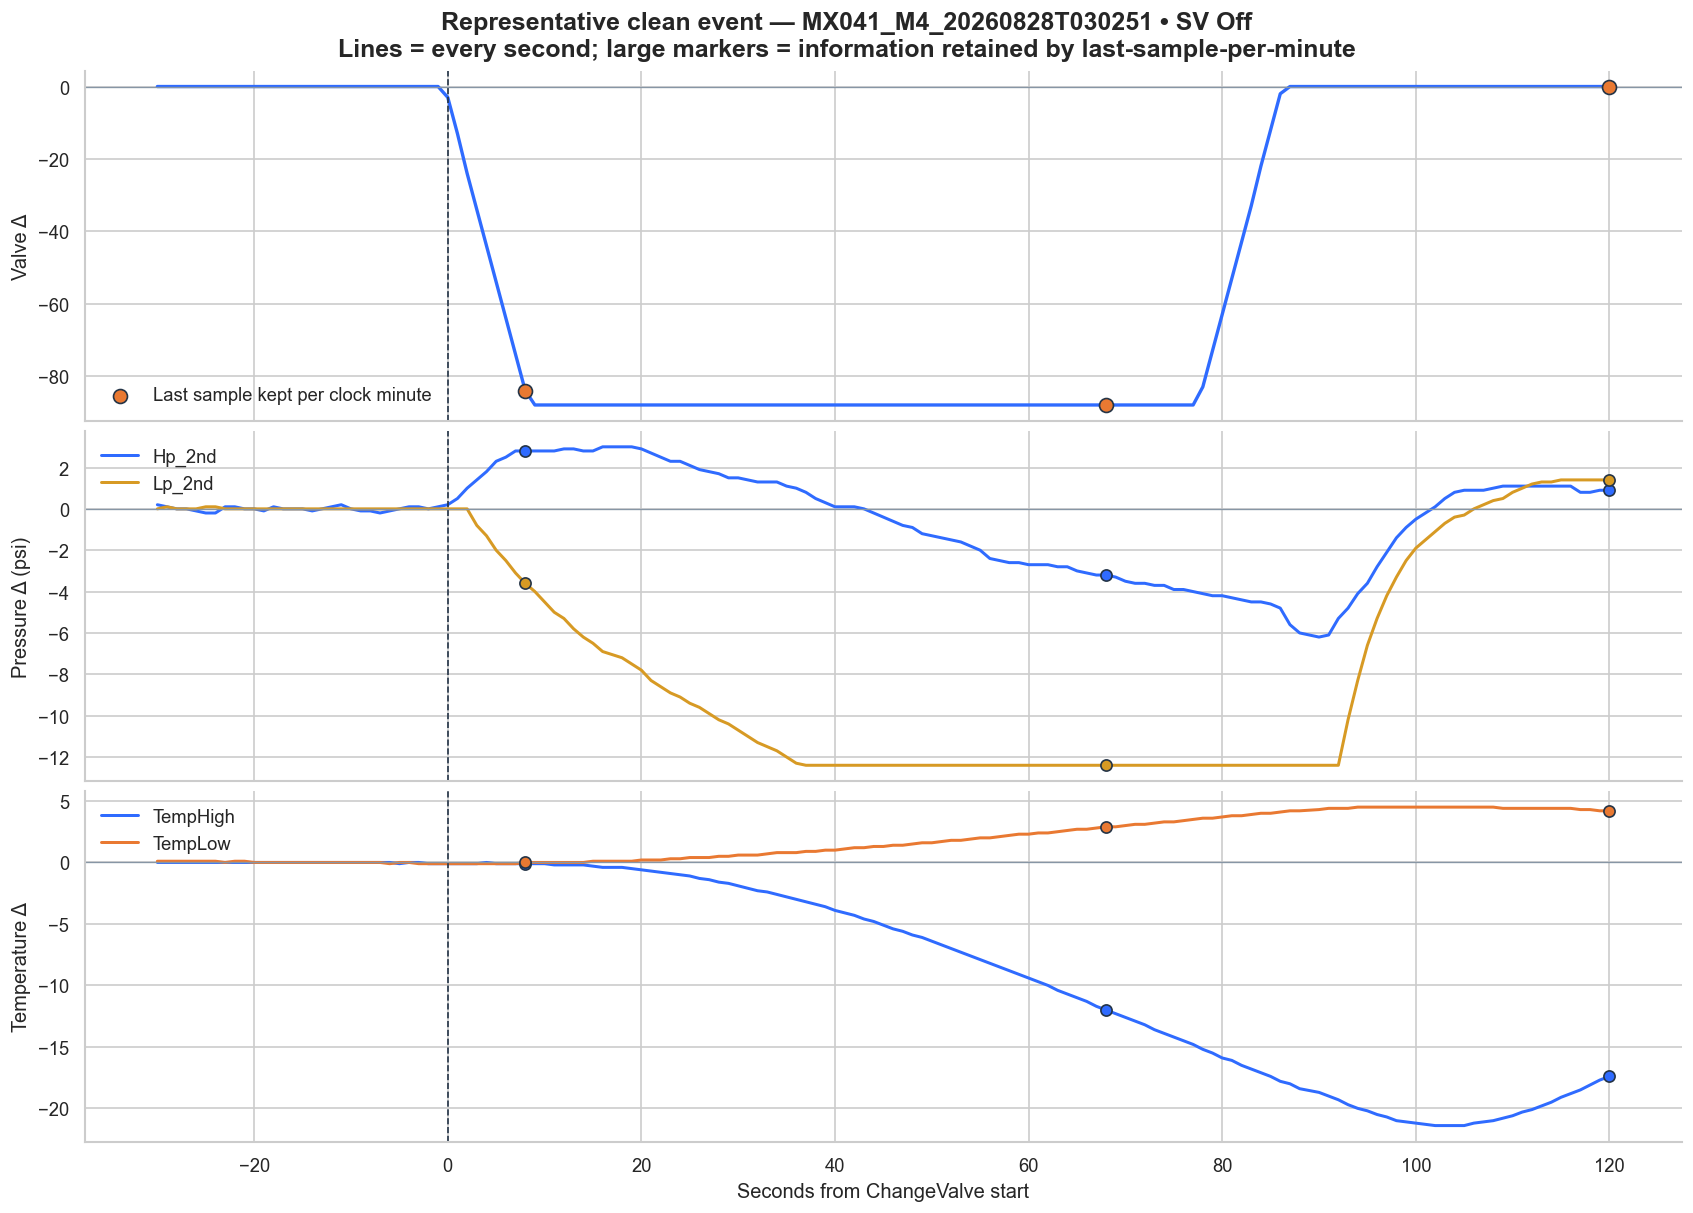

In [8]:
most_common_direction = direction_counts.idxmax()
profile_counts = (
    event_pd[event_pd["direction"] == most_common_direction]
    .groupby(["machine_number", "module", "sv"]).size().sort_values(ascending=False)
)
representative_profile = profile_counts.index[0]
profile_events = event_pd[
    (event_pd["machine_number"] == representative_profile[0])
    & (event_pd["module"] == representative_profile[1])
    & (event_pd["sv"] == representative_profile[2])
    & (event_pd["direction"] == most_common_direction)
].copy()
profile_events["cp2_response_60s"] = (
    profile_events["hp2_response_60s"].abs() + profile_events["lp2_response_60s"].abs()
)
median_strength = profile_events["cp2_response_60s"].median()
representative_event = profile_events.iloc[(profile_events["cp2_response_60s"] - median_strength).abs().argmin()]
example = trajectory_pd[trajectory_pd["event_id"] == representative_event["event_id"]].sort_values("observed_at").copy()
example["clock_minute"] = example["observed_at"].dt.floor("min")
minute_last = example.groupby("clock_minute", as_index=False).tail(1)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, constrained_layout=True)
axes[0].plot(example["relative_second"], example["valve_delta"], color=PALETTE["blue"], lw=2)
axes[0].scatter(minute_last["relative_second"], minute_last["valve_delta"], color=PALETTE["orange"], s=70,
                edgecolor=PALETTE["ink"], label="Last sample kept per clock minute", zorder=3)
axes[0].set_ylabel("Valve Δ")
axes[0].legend(frameon=False)

for metric, color in [("hp2", PALETTE["blue"]), ("lp2", PALETTE["gold"])]:
    axes[1].plot(example["relative_second"], example[f"{metric}_delta"], color=color, lw=1.8, label=TARGET_LABELS[metric])
    axes[1].scatter(minute_last["relative_second"], minute_last[f"{metric}_delta"], color=color, s=45,
                    edgecolor=PALETTE["ink"], zorder=3)
axes[1].set_ylabel("Pressure Δ (psi)")
axes[1].legend(frameon=False)

for metric, color in [("temphi", PALETTE["blue"]), ("templo", PALETTE["orange"])]:
    axes[2].plot(example["relative_second"], example[f"{metric}_delta"], color=color, lw=1.8, label=TARGET_LABELS[metric])
    axes[2].scatter(minute_last["relative_second"], minute_last[f"{metric}_delta"], color=color, s=45,
                    edgecolor=PALETTE["ink"], zorder=3)
axes[2].set_ylabel("Temperature Δ")
axes[2].set_xlabel("Seconds from ChangeValve start")
axes[2].legend(frameon=False)

for ax in axes:
    ax.axvline(0, color=PALETTE["ink"], ls="--", lw=1)
    ax.axhline(0, color=PALETTE["grey"], lw=.8)
    sns.despine(ax=ax)
fig.suptitle(
    f"Representative clean event — {representative_event['event_id']} • SV {representative_event['sv']}\n"
    "Lines = every second; large markers = information retained by last-sample-per-minute",
    fontsize=15, fontweight="bold",
)
savefig("03_representative_event_1s_vs_1m.png")
plt.show()

จุดใหญ่ไม่สามารถบอกได้ว่า Valve เริ่มเปลี่ยนที่วินาทีใด, pressure เริ่มตอบหลังจากกี่วินาที,
response สูงสุดเมื่อไร หรือมี hunting ระหว่างนาทีหรือไม่ ข้อมูลเหล่านี้หายถ้า downsample ก่อนสร้าง feature.

### 8. Correlation magnitude versus response timing

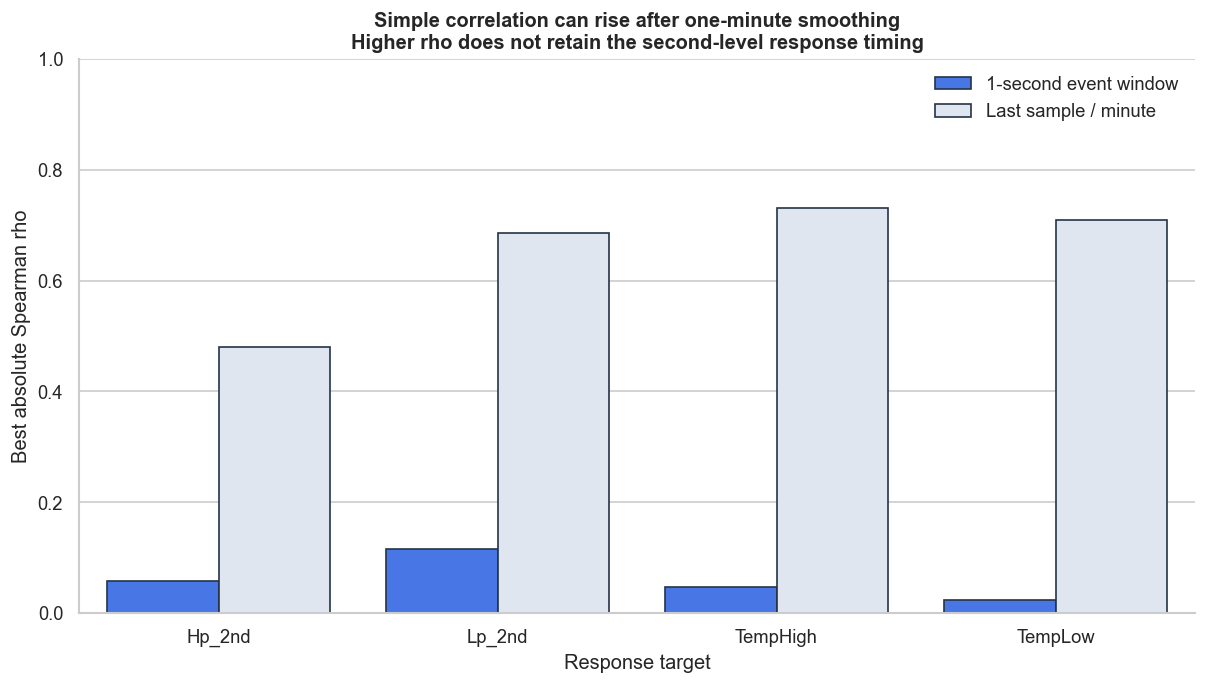

,target,method,best_abs_rho,signed_rho,best_lag,pairs
0,Hp_2nd,1-second event window,0.058078,0.058078,5 s,2203
1,Hp_2nd,Last sample / minute,0.479585,0.479585,0 min,583
2,Lp_2nd,1-second event window,0.115942,0.115942,0 s,2243
3,Lp_2nd,Last sample / minute,0.685567,0.685567,0 min,583
4,TempHigh,1-second event window,0.047108,-0.047108,0 s,2243
5,TempHigh,Last sample / minute,0.730205,0.730205,1 min,340
6,TempLow,1-second event window,0.024221,0.024221,0 s,2243
7,TempLow,Last sample / minute,0.710002,-0.710002,1 min,340


In [9]:
def safe_spearman(x, y, min_pairs=30):
    frame = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(frame) < min_pairs or frame["x"].nunique() < 3 or frame["y"].nunique() < 3:
        return np.nan, len(frame)
    return float(spearmanr(frame["x"], frame["y"]).statistic), len(frame)

def second_impulse_relationship(data, target):
    rows = []
    for event_id, event in data.groupby("event_id"):
        event = event.sort_values("relative_second").set_index("relative_second")
        dvalve = event["valve_delta"].diff()
        command_seconds = dvalve.index[(dvalve.abs() > 0) & dvalve.index.to_series().between(0, 30)]
        for command_second in command_seconds:
            for lag in range(0, 61, 5):
                start = command_second + lag
                end = start + 5
                if start in event.index and end in event.index:
                    rows.append({"lag": lag, "x": dvalve.loc[command_second],
                                 "y": event.loc[end, f"{target}_delta"] - event.loc[start, f"{target}_delta"]})
    pairs = pd.DataFrame(rows)
    results = []
    for lag, part in pairs.groupby("lag"):
        rho, n = safe_spearman(part["x"], part["y"], min_pairs=50)
        results.append({"lag": lag, "rho": rho, "n": n})
    result = pd.DataFrame(results).dropna(subset=["rho"])
    return result.iloc[result["rho"].abs().argmax()] if not result.empty else pd.Series({"lag": np.nan, "rho": np.nan, "n": 0})

def minute_last_relationship(data, target):
    minute = data.sort_values("observed_at").copy()
    minute["clock_minute"] = minute["observed_at"].dt.floor("min")
    minute = minute.groupby(["event_id", "clock_minute"], as_index=False).tail(1)
    minute["dvalve"] = minute.groupby("event_id")["valve_delta"].diff()
    minute["dtarget"] = minute.groupby("event_id")[f"{target}_delta"].diff()
    best = {"lag": np.nan, "rho": np.nan, "n": 0}
    for lag in [0, 1, 2]:
        future = minute.groupby("event_id")["dtarget"].shift(-lag)
        rho, n = safe_spearman(minute["dvalve"], future, min_pairs=30)
        if np.isfinite(rho) and (not np.isfinite(best["rho"]) or abs(rho) > abs(best["rho"])):
            best = {"lag": lag, "rho": rho, "n": n}
    return pd.Series(best)

retention_rows = []
for target in TARGETS:
    second_result = second_impulse_relationship(trajectory_pd, target)
    minute_result = minute_last_relationship(trajectory_pd, target)
    retention_rows += [
        {"target": TARGET_LABELS[target], "method": "1-second event window", "best_abs_rho": abs(second_result["rho"]),
         "signed_rho": second_result["rho"], "best_lag": f"{int(second_result['lag'])} s" if np.isfinite(second_result["lag"]) else "n/a", "pairs": int(second_result["n"])},
        {"target": TARGET_LABELS[target], "method": "Last sample / minute", "best_abs_rho": abs(minute_result["rho"]),
         "signed_rho": minute_result["rho"], "best_lag": f"{int(minute_result['lag'])} min" if np.isfinite(minute_result["lag"]) else "n/a", "pairs": int(minute_result["n"])},
    ]
retention = pd.DataFrame(retention_rows)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=retention, x="target", y="best_abs_rho", hue="method",
            palette=[PALETTE["blue"], PALETTE["light"]], edgecolor=PALETTE["ink"], ax=ax)
ax.set_ylim(0, 1)
ax.set_ylabel("Best absolute Spearman rho")
ax.set_xlabel("Response target")
ax.set_title("Simple correlation can rise after one-minute smoothing\nHigher rho does not retain the second-level response timing")
ax.legend(title="", frameon=False)
sns.despine()
savefig("04_relationship_retention_1s_vs_1m.png")
plt.show()
display(retention)

ค่า correlation นี้เป็น diagnostic บน events ชุดเดียวกัน ไม่ใช่คะแนนความแม่นยำของโมเดลหรือ causal effect.
ผลที่ `last sample / minute` มี rho สูงกว่าเกิดได้จากการ smoothing และการรวม shared trend ของ control sequence
แต่ snapshot ยังตอบไม่ได้ว่า response เริ่มที่วินาทีใด, peak เมื่อไร หรือ Valve กลับตำแหน่งเมื่อไร.

ดังนั้น “rho สูงกว่า” ไม่เท่ากับ “รักษาความสัมพันธ์เชิงเวลาได้ดีกว่า”; สำหรับ ML ควรเก็บทั้ง minute-level baseline
และ second-derived response features.

## Response-Preserving One-Minute Features

### 9. Aggregate features after extracting second-level behavior

In [10]:
event_pd["event_minute"] = event_pd["event_at"].dt.floor("min")
aggregate_spec = {
    "event_count": ("event_id", "nunique"),
    "valve_net_step": ("valve_step", "sum"),
    "valve_max_abs_step": ("valve_step", lambda s: s.abs().max()),
    "valve_total_variation": ("valve_total_variation", "sum"),
    "valve_step_count": ("valve_step_count", "sum"),
    "valve_post_slope_30s": ("valve_post_slope_30s", "median"),
}
for target in TARGETS:
    for lag in [5, 15, 30, 60, 120]:
        aggregate_spec[f"{target}_response_{lag}s"] = (f"{target}_response_{lag}s", "median")
    aggregate_spec[f"{target}_peak_abs"] = (f"{target}_peak_abs", "max")
    aggregate_spec[f"{target}_peak_lag_s"] = (f"{target}_peak_lag_s", "median")
    aggregate_spec[f"{target}_pre_slope"] = (f"{target}_pre_slope", "median")
    aggregate_spec[f"{target}_post_slope_30s"] = (f"{target}_post_slope_30s", "median")
    aggregate_spec[f"{target}_best_lag_s"] = (f"{target}_best_lag_s", "median")
    aggregate_spec[f"{target}_best_lag_rho"] = (f"{target}_best_lag_rho", "median")

minute_response_features = (
    event_pd.groupby(["machine_number", "module", "sv", "event_minute", "direction"], as_index=False)
    .agg(**aggregate_spec)
)
MINUTE_FEATURE_PATH = OUTPUT_ROOT / "minute_response_features.parquet"
pl.from_pandas(minute_response_features).write_parquet(MINUTE_FEATURE_PATH, compression="zstd")

feature_dictionary = pd.DataFrame([
    ["event_count", "จำนวน ChangeValve sequences ในนาทีนั้น", "ทันทีเมื่อจบนาที"],
    ["valve_net_step / max_abs_step", "ขนาดและทิศทาง command จาก raw 1 s", "ทันทีเมื่อจบนาที"],
    ["valve_total_variation / step_count", "ปริมาณการแกว่งและจำนวน step เพื่อจับ hunting", "finalize หลัง 120 s"],
    ["valve_post_slope_30s", "ความเร็วของคำสั่ง valve ใน 30 วินาทีแรก", "พร้อมหลัง 30 s"],
    ["*_response_5s/15s/30s", "pressure/temperature response ระยะต้น", "ภายในนาทีเดียว"],
    ["*_response_60s/120s", "response ระยะกลาง", "finalize ช้า 1–2 นาที"],
    ["*_peak_abs", "ขนาด response สูงสุดใน window", "finalize หลัง 120 s"],
    ["*_peak_lag_s", "เวลาถึง response สูงสุด", "finalize หลัง 120 s"],
    ["*_pre_slope / *_post_slope_30s", "แนวโน้มก่อน event และ response slope ช่วงต้น", "พร้อมหลัง 30 s"],
    ["*_best_lag_s / *_best_lag_rho", "lag ที่สัมพันธ์กับ valve มากที่สุดและทิศทาง rho", "พร้อมหลัง 120 s"],
])
feature_dictionary.columns = ["Minute feature", "What it preserves from 1-second data", "Online availability"]
display(feature_dictionary)
display(minute_response_features.head(10))
print("Saved:", MINUTE_FEATURE_PATH)

,Minute feature,What it preserves from 1-second data,Online availability
0,event_count,จำนวน ChangeValve sequences ในนาทีนั้น,ทันทีเมื่อจบนาที
1,valve_net_step / max_abs_step,ขนาดและทิศทาง command จาก raw 1 s,ทันทีเมื่อจบนาที
2,valve_total_variation / step_count,ปริมาณการแกว่งและจำนวน step เพื่อจับ hunting,finalize หลัง 120 s
3,valve_post_slope_30s,ความเร็วของคำสั่ง valve ใน 30 วินาทีแรก,พร้อมหลัง 30 s
4,*_response_5s/15s/30s,pressure/temperature response ระยะต้น,ภายในนาทีเดียว
5,*_response_60s/120s,response ระยะกลาง,finalize ช้า 1–2 นาที
6,*_peak_abs,ขนาด response สูงสุดใน window,finalize หลัง 120 s
7,*_peak_lag_s,เวลาถึง response สูงสุด,finalize หลัง 120 s
8,*_pre_slope / *_post_slope_30s,แนวโน้มก่อน event และ response slope ช่วงต้น,พร้อมหลัง 30 s
9,*_best_lag_s / *_best_lag_rho,lag ที่สัมพันธ์กับ valve มากที่สุดและทิศทาง rho,พร้อมหลัง 120 s


,machine_number,module,sv,event_minute,direction,event_count,valve_net_step,valve_max_abs_step,valve_total_variation,valve_step_count,...,templo_response_15s,templo_response_30s,templo_response_60s,templo_response_120s,templo_peak_abs,templo_peak_lag_s,templo_pre_slope,templo_post_slope_30s,templo_best_lag_s,templo_best_lag_rho
0,017,1,Off,2026-08-30 01:07:00,Closing,1,-97.0,97.0,184.0,20,...,0.30,4.30,11.10,20.20,20.20,119.0,3.529412e-03,0.148185,60.0,-0.653652
1,017,1,Off,2026-08-30 01:23:00,Closing,1,-90.0,90.0,211.0,23,...,2.65,3.95,6.45,10.05,10.15,104.0,1.210294e-01,0.083794,60.0,-0.629180
2,017,2,Off,2026-08-30 01:23:00,Closing,1,-89.0,89.0,195.0,21,...,-7.85,-9.65,-6.65,2.25,9.65,28.0,-1.032353e-01,-0.288503,60.0,-0.625705
3,017,3,Off,2026-08-30 01:23:00,Closing,1,-87.0,87.0,202.0,22,...,0.75,1.35,3.15,9.25,9.35,120.0,2.808824e-02,0.033291,55.0,-0.625640
4,017,4,Off,2026-08-10 20:35:00,Closing,1,-88.0,88.0,158.0,17,...,-0.30,2.20,9.30,21.90,22.00,120.0,-1.176471e-03,0.062354,30.0,-0.625650
5,017,4,Off,2026-08-30 01:23:00,Closing,1,-88.0,88.0,204.0,22,...,0.00,2.70,8.70,19.40,19.50,120.0,-1.279412e-02,0.093551,25.0,-0.625650
6,017,5,Off,2026-08-30 01:23:00,Closing,1,-83.0,83.0,160.0,17,...,-0.30,1.00,6.70,16.80,16.90,120.0,-4.779870e-15,0.020396,25.0,-0.595129
7,017,6,Off,2026-08-30 01:23:00,Closing,1,-95.0,95.0,174.0,18,...,-0.40,1.10,7.10,16.70,16.90,120.0,-3.013386e-15,0.021954,60.0,-0.625668
8,017,8,Off,2026-08-20 04:06:00,Closing,1,-99.0,99.0,179.0,20,...,0.40,3.90,11.50,19.50,19.60,116.0,1.102941e-02,0.133831,60.0,-0.654820
9,017,8,Off,2026-08-20 07:50:00,Closing,1,-98.0,98.0,193.0,20,...,-0.80,2.30,10.80,12.00,16.80,91.0,-4.573529e-02,0.102735,55.0,-0.653938


Saved: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_1s_window_analysis\minute_response_features.parquet


### วิธีสร้างตารางหนึ่งนาทีที่ยังเห็นความสัมพันธ์ระดับวินาที

```text
Raw 1-second rows
   ├─ state segmentation: machine × module × SV
   ├─ detect Valve event and reject mixed-state windows
   ├─ compute within-minute microstructure
   │    ├─ median / IQR / P05–P95 / range
   │    ├─ first / last / net change / slope
   │    ├─ Valve total variation / step count / largest step
   │    └─ seconds with missing data
   └─ compute event-response features
        ├─ ΔPressure at 5/15/30/60/120 s
        ├─ best lag / peak / gain / settling
        └─ assign features to event_start_minute
                         ↓
One row per machine × module × SV × minute
```

สิ่งที่ **ทำไม่ได้** คือเก็บเพียง last/mean/median หนึ่งค่าแล้วพยายาม reconstruct lag ระดับวินาทีภายหลัง
เพราะ timestamp ของ event, ลำดับการเปลี่ยน, peak และ response delay ถูกทิ้งไปแล้ว.

สำหรับระบบ online ให้มีสองชุด:

- **Fast features:** 5/15/30 วินาที ใช้ได้ภายในนาทีเดียว
- **Complete features:** 60/120 วินาที finalize ย้อนกลับไปยัง event minute ด้วย latency 1–2 นาที

ในการ split train/validation ต้องอิงเวลาที่ feature “พร้อมใช้งานจริง” เพื่อป้องกัน look-ahead leakage.

## Takeaways

### 10. Build the executed summary and export evidence

In [11]:
closing_curve = curve[curve["direction"] == "Closing"]
closing_median_response = {}
for lag in [5, 15, 30, 60, 120]:
    closing_median_response[f"{lag}s"] = {}
    for target in TARGETS:
        value = closing_curve.loc[closing_curve["relative_second"] == lag, f"{target}_median"]
        closing_median_response[f"{lag}s"][target] = float(value.iloc[0]) if not value.empty else None

profile_count = event_pd[["machine_number", "module", "sv", "direction"]].drop_duplicates().shape[0]
summary = {
    "one_second_interval_pct": float(one_second_pct),
    "candidate_event_count": int(cadence["candidate_event_count"]),
    "clean_event_count": int(len(event_pd)),
    "closing_event_count": int((event_pd["direction"] == "Closing").sum()),
    "opening_event_count": int((event_pd["direction"] == "Opening").sum()),
    "machines_with_clean_events": int(event_pd["machine_number"].nunique()),
    "clean_profiles": int(profile_count),
    "closing_median_response": closing_median_response,
    "representative_event_id": representative_event["event_id"],
    "retention": retention.to_dict(orient="records"),
    "caveats": [
        "No recipe/load/actual controlled-temperature context is available.",
        "Clean event selection excludes file-boundary windows and overlapping control sequences.",
        "Observed time-linked response is not proof of causality or failure type.",
        "Complete 120-second features introduce 1–2 minute online latency.",
    ],
}
(OUTPUT_ROOT / "analysis_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
event_summary.write_csv(OUTPUT_ROOT / "clean_event_summary.csv")
pl.from_pandas(retention).write_csv(OUTPUT_ROOT / "relationship_retention.csv")

display(Markdown(f'''
### สรุปจากผลที่รันจริง

- Raw cadence = **{one_second_pct:.2f}% exact 1-second intervals** ภายในไฟล์
- จาก ChangeValve starts **{cadence['candidate_event_count']:,}** ครั้ง เหลือ clean comparable windows **{len(event_pd):,}** ครั้ง
- ครอบคลุม **{event_pd['machine_number'].nunique()} เครื่อง** และ {profile_count} machine–module–SV–direction profiles
- Opening มีเพียง **{(event_pd['direction'] == 'Opening').sum():,} events** จึงยังไม่เพียงพอสำหรับ aggregate curve; ผลหลักรายงานเฉพาะ closing
- Closing median ที่ +60 s: `Hp_2nd {closing_median_response['60s']['hp2']:+.1f} psi`, `Lp_2nd {closing_median_response['60s']['lp2']:+.1f} psi`
- Closing median ที่ +120 s: `TempHigh {closing_median_response['120s']['temphi']:+.1f}`, `TempLow {closing_median_response['120s']['templo']:+.1f}`
- ความสัมพันธ์ระดับวินาทีควรส่งเข้า ML ผ่าน response-preserving minute features ไม่ใช่ raw snapshot เพียงค่าเดียว

**ข้อจำกัด:** ไม่มี recipe/load/actual controlled temperature จึงยังแยก ATC demand ออกจาก causal valve effect ไม่สมบูรณ์
และผลนี้ไม่ใช่หลักฐาน leak/undercharge.
'''))


### สรุปจากผลที่รันจริง

- Raw cadence = **98.55% exact 1-second intervals** ภายในไฟล์
- จาก ChangeValve starts **2,971** ครั้ง เหลือ clean comparable windows **243** ครั้ง
- ครอบคลุม **12 เครื่อง** และ 77 machine–module–SV–direction profiles
- Opening มีเพียง **2 events** จึงยังไม่เพียงพอสำหรับ aggregate curve; ผลหลักรายงานเฉพาะ closing
- Closing median ที่ +60 s: `Hp_2nd -10.9 psi`, `Lp_2nd -12.7 psi`
- Closing median ที่ +120 s: `TempHigh -16.8`, `TempLow +8.3`
- ความสัมพันธ์ระดับวินาทีควรส่งเข้า ML ผ่าน response-preserving minute features ไม่ใช่ raw snapshot เพียงค่าเดียว

**ข้อจำกัด:** ไม่มี recipe/load/actual controlled temperature จึงยังแยก ATC demand ออกจาก causal valve effect ไม่สมบูรณ์
และผลนี้ไม่ใช่หลักฐาน leak/undercharge.


## QA Checklist

- [x] แยก machine, module, SV และทิศทาง Valve
- [x] ตัด Stop→Run, MValveHome, Valve ติดลบ และ mixed-SV window
- [x] ใช้ pre-event reference ก่อนคำนวณ response
- [x] แสดง event count/coverage เพื่อไม่ให้ sample น้อยดูน่าเชื่อถือเกินจริง
- [x] เปรียบเทียบ 1-second กับ last-sample-per-minute บน accepted events ชุดเดียวกัน
- [x] ระบุ online feature latency และ look-ahead risk
- [x] ไม่ตีความ correlation เป็น causality, leak หรือ health label

**Source artifacts:** raw Parquet ใต้ `HT9046MX-20260902T013607Z-1-001/HT9046MX/raw/table=ht9046mx_readings`
และ `README_System.md` เป็น data contract.